# LLM 标注性能评估 — 三模型 × 两种提示词 × 两个维度

**任务**：以 4 位人工标注员的多数票结果为金标准，评估三个 LLM（MiMo / Deepseek / Qwen）在
「负面性」「侮辱性」两个二分类标签上的 **Accuracy / Precision / Recall / F1**。

## 数据来源

| 文件 | 内容 | 提示词模式 |
| --- | --- | --- |
| `Data/Human/Human_Result.csv` | 金标准 420 条 × 2 维 | 人工 4 人多数票 |
| `Data/LLM/LLM_prompt_predictions.csv` | 三模型预测 | **提示词工程** engineered（①+②+③+④） |
| `Data/LLM/LLM_predictions.csv` | 三模型预测 | **零样本** zero_shot（①+②+③） |

> 两个 LLM 文件仅在提示词模块 ④「额外提示词」上有差异，模型、样本、温度完全一致。
> 因此本 notebook 除了给出六组绝对指标，还能做 **提示词工程的增量效果** 与 **配对显著性检验**。

## 指标口径

正类 = **1**（该评论具有负面性 / 侮辱性）。

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{Precision}=\frac{TP}{TP+FP}\qquad \text{Recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2PR}{P+R}$$

- 主指标按 **正类（1）** 计算，与「识别出多少负面 / 侮辱内容」的研究关注点一致
- 同时给出 **Macro-F1**（两类等权），用于校正类别不平衡
- ⚠️「侮辱性」正类仅占约 10%，**Accuracy 会被多数类主导**（全判 0 也能到 89%），解读请以 P / R / F1 为主

In [1]:
# ===== 环境与路径 =====
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# 兼容两种工作目录：仓库根目录 / scripts 子目录
CWD = Path.cwd()
PROJ = CWD if (CWD / "Data").exists() else CWD.parent

HUMAN_PATH = PROJ / "Data" / "Human" / "Human_Result.csv"
HUMAN_RAW = PROJ / "Data" / "Human" / "Human.csv"
MODE_FILES = {
    "engineered": PROJ / "Data" / "LLM" / "LLM_prompt_predictions.csv",  # 提示词工程 ①+②+③+④
    "zero_shot":  PROJ / "Data" / "LLM" / "LLM_predictions.csv",         # 零样本     ①+②+③
}
MODE_CN = {"engineered": "提示词工程", "zero_shot": "零样本"}
MODES_ORDER = ["提示词工程", "零样本"]

MODELS = ["MiMo", "Deepseek", "Qwen"]
DIMS = ["负面性", "侮辱性"]
METRICS = ["Accuracy", "Precision", "Recall", "F1"]
POS = 1  # 正类标签

ALL_FILES = [HUMAN_PATH, HUMAN_RAW, *MODE_FILES.values()]

In [2]:
# 读取数据
human = pd.read_csv(HUMAN_PATH)
llm = {mode: pd.read_csv(path) for mode, path in MODE_FILES.items()}

print(f"金标准 Human_Result.csv : {human.shape}")
for mode, df in llm.items():
    print(f"{MODE_CN[mode]:<5}（{mode:<10}）: {df.shape}   <- {MODE_FILES[mode].name}")

print("\n金标准列：", human.columns.tolist())
print("LLM 列  ：", llm["engineered"].columns.tolist())

金标准 Human_Result.csv : (420, 4)
提示词工程（engineered）: (420, 8)   <- LLM_prompt_predictions.csv
零样本  （zero_shot ）: (420, 8)   <- LLM_predictions.csv

金标准列： ['类型', '评论', '负面性标签', '侮辱性标签']
LLM 列  ： ['类型', '评论', '负面性MiMo', '侮辱性MiMo', '负面性Deepseek', '侮辱性Deepseek', '负面性Qwen', '侮辱性Qwen']


## 一、数据对齐

三个文件必须**逐行严格对应**才有可比性 —— 这里按「评论」原文与「类型」逐行校验，
任何一处不一致就中断，避免错位计算出一堆好看但错误的数字。

In [3]:
# ===== 逐行对齐校验 =====
ref_text = human["评论"].astype(str).to_numpy()
ref_type = human["类型"].astype(str).to_numpy()
pred_cols = [f"{d}{m}" for d in DIMS for m in MODELS]

rows = []
for mode, df in llm.items():
    rows.append({
        "文件": MODE_FILES[mode].name,
        "模式": MODE_CN[mode],
        "行数": len(df),
        "评论逐行一致": bool((df["评论"].astype(str).to_numpy() == ref_text).all()),
        "类型逐行一致": bool((df["类型"].astype(str).to_numpy() == ref_type).all()),
        "预测值缺失": int(df[pred_cols].isna().sum().sum()),
    })
align = pd.DataFrame(rows)

assert (align["行数"] == len(human)).all(), "行数不一致"
assert align["评论逐行一致"].all() and align["类型逐行一致"].all(), "行未对齐，禁止后续计算"
assert (align["预测值缺失"] == 0).all(), "存在缺失预测，请先处理"

print("三份文件的评论与类型逐行完全一致，无缺失值，可放心比较。")
align

三份文件的评论与类型逐行完全一致，无缺失值，可放心比较。


,文件,模式,行数,评论逐行一致,类型逐行一致,预测值缺失
0,LLM_prompt_predictions.csv,提示词工程,420,True,True,0
1,LLM_predictions.csv,零样本,420,True,True,0


In [4]:
# ===== 金标准标签分布 =====
overall = pd.DataFrame({
    "样本数": [len(human)],
    "负面性正类数": [int(human["负面性标签"].sum())],
    "负面性正类占比": [human["负面性标签"].mean()],
    "侮辱性正类数": [int(human["侮辱性标签"].sum())],
    "侮辱性正类占比": [human["侮辱性标签"].mean()],
}, index=["全部样本"])

TYPE_ORDER = ["正常差评", "语气型差评", "声音型差评", "视觉型差评"]
TYPE_ORDER_FULL = ["好评", *TYPE_ORDER]

counts = (human.groupby("类型")
          .agg(样本数=("评论", "size"),
               负面性_正类=("负面性标签", lambda s: int((s == 1).sum())),
               负面性_负类=("负面性标签", lambda s: int((s == 0).sum())),
               侮辱性_正类=("侮辱性标签", lambda s: int((s == 1).sum())),
               侮辱性_负类=("侮辱性标签", lambda s: int((s == 0).sum())))
          .reindex(TYPE_ORDER_FULL))

display(overall.round(4))
display(counts)

print("注：「好评」类在两个维度上都没有正类样本，其 Recall / Precision / F1 无定义；")
print("    该类的评估价值在于「误报率」，见第三部分。")

,样本数,负面性正类数,负面性正类占比,侮辱性正类数,侮辱性正类占比
全部样本,420,236,0.5619,45,0.1071


,样本数,负面性_正类,负面性_负类,侮辱性_正类,侮辱性_负类
类型,,,,,
好评,182,0,182,0,182
正常差评,114,112,2,0,114
语气型差评,73,73,0,6,67
声音型差评,30,30,0,22,8
视觉型差评,21,21,0,17,4


注：「好评」类在两个维度上都没有正类样本，其 Recall / Precision / F1 无定义；
    该类的评估价值在于「误报率」，见第三部分。


## 二、总体指标（核心结果）

In [5]:
# ===== 指标函数（正类 = 1）=====
def evaluate(y_true, y_pred) -> dict:
    '''二分类指标。正类固定为 1，并额外返回 Macro-F1 与混淆矩阵四元组。'''
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=POS, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=POS, zero_division=0),
        "F1": f1_score(y_true, y_pred, pos_label=POS, zero_division=0),
        "MacroF1": f1_score(y_true, y_pred, average="macro", labels=[0, 1], zero_division=0),
        "TP": int(((y_true == 1) & (y_pred == 1)).sum()),
        "FP": int(((y_true == 0) & (y_pred == 1)).sum()),
        "FN": int(((y_true == 1) & (y_pred == 0)).sum()),
        "TN": int(((y_true == 0) & (y_pred == 0)).sum()),
    }


def ordered_pivot(df, row_key, col_key, value_keys, row_order, col_order):
    '''按给定顺序构造 MultiIndex 透视表。

    pandas 3.0 下 pivot(values=[...]) 的列层级顺序不稳定、实测会错位，
    这里手工组装字典再索引，保证顺序与取值完全可控。
    '''
    lut = {(rec[row_key], rec[col_key]): [rec[k] for k in value_keys]
           for _, rec in df.iterrows()}
    missing = [(r, c) for r in row_order for c in col_order if (r, c) not in lut]
    assert not missing, f"透视表缺格：{missing}"
    data = [[lut[(r, c)][j] for c in col_order for j in range(len(value_keys))]
            for r in row_order]
    cols = pd.MultiIndex.from_product([col_order, value_keys])
    return pd.DataFrame(data, index=pd.Index(row_order, name=row_key), columns=cols)

In [6]:
# ===== 计算主结果：2 维度 × 2 模式 × 3 模型 = 12 组 =====
records = []
for dim in DIMS:
    y_true = human[f"{dim}标签"].to_numpy()
    for mode in ["engineered", "zero_shot"]:
        for model in MODELS:
            y_pred = llm[mode][f"{dim}{model}"].to_numpy()
            records.append({"维度": dim, "提示词模式": mode, "模型": model,
                            **evaluate(y_true, y_pred)})

results = pd.DataFrame(records)
results["模式"] = results["提示词模式"].map(MODE_CN)
print("已计算", len(results), "组指标。")

# ===== 主结果总表：可直接用于结果汇报 =====
final_table = (results[["维度", "模式", "模型", *METRICS, "MacroF1", "TP", "FP", "FN", "TN"]]
               .sort_values(["维度", "模式", "模型"], ascending=[True, False, True])
               .round(4).reset_index(drop=True))
final_table

已计算 12 组指标。


,维度,模式,模型,Accuracy,Precision,Recall,F1,MacroF1,TP,FP,FN,TN
0,侮辱性,零样本,Deepseek,0.9643,0.9688,0.6889,0.8052,0.8928,31,1,14,374
1,侮辱性,零样本,MiMo,0.9548,0.8095,0.7556,0.7816,0.8782,34,8,11,367
2,侮辱性,零样本,Qwen,0.9571,0.8293,0.7556,0.7907,0.8834,34,7,11,368
3,侮辱性,提示词工程,Deepseek,0.9619,0.9677,0.6667,0.7895,0.8843,30,1,15,374
4,侮辱性,提示词工程,MiMo,0.9667,0.9429,0.7333,0.8250,0.9033,33,2,12,373
5,侮辱性,提示词工程,Qwen,0.9643,0.9412,0.7111,0.8101,0.8952,32,2,13,373
6,负面性,零样本,Deepseek,0.9762,0.9788,0.9788,0.9788,0.9758,231,5,5,179
7,负面性,零样本,MiMo,0.9786,0.9671,0.9958,0.9812,0.9781,235,8,1,176
8,负面性,零样本,Qwen,0.9810,0.9872,0.9788,0.9830,0.9807,231,3,5,181
9,负面性,提示词工程,Deepseek,0.9738,0.9787,0.9746,0.9766,0.9734,230,5,6,179


In [7]:
# ===== 参照基线：'全判多数类'的退化模型 =====
# 用来说明为什么不平衡任务不能只看 Accuracy：全判 0 的模型 Accuracy 很高但 F1 = 0。
base_rows = []
for dim in DIMS:
    y_true = human[f"{dim}标签"].to_numpy()
    for name, const in [("全判 1", np.ones_like(y_true)), ("全判 0", np.zeros_like(y_true))]:
        m = evaluate(y_true, const)
        base_rows.append({"维度": dim, "退化模型": name,
                          **{k: m[k] for k in [*METRICS, "MacroF1"]}})
pd.DataFrame(base_rows).round(4)

,维度,退化模型,Accuracy,Precision,Recall,F1,MacroF1
0,负面性,全判 1,0.5619,0.5619,1.0,0.7195,0.3598
1,负面性,全判 0,0.4381,0.0000,0.0,0.0000,0.3046
2,侮辱性,全判 1,0.1071,0.1071,1.0,0.1935,0.0968
3,侮辱性,全判 0,0.8929,0.0000,0.0,0.0000,0.4717


In [8]:
# ===== 分维度透视表：模型 × 提示词模式 =====
for dim in DIMS:
    n_pos = int(human[f"{dim}标签"].sum())
    print("=" * 82)
    print(f"{dim}   （正类=1；金标准正类 {n_pos}/{len(human)} = {n_pos/len(human):.1%}）")
    print("=" * 82)
    sub = results[results["维度"] == dim]
    display(ordered_pivot(sub, "模型", "模式", METRICS, MODELS, MODES_ORDER).round(4))

负面性   （正类=1；金标准正类 236/420 = 56.2%）


提示词工程                                零样本                          
         Accuracy Precision  Recall      F1 Accuracy Precision  Recall      F1
模型                                                                            
MiMo       0.9786    0.9671  0.9958  0.9812   0.9786    0.9671  0.9958  0.9812
Deepseek   0.9738    0.9787  0.9746  0.9766   0.9762    0.9788  0.9788  0.9788
Qwen       0.9714    0.9956  0.9534  0.9740   0.9810    0.9872  0.9788  0.9830

侮辱性   （正类=1；金标准正类 45/420 = 10.7%）


提示词工程                                零样本                          
         Accuracy Precision  Recall      F1 Accuracy Precision  Recall      F1
模型                                                                            
MiMo       0.9667    0.9429  0.7333  0.8250   0.9548    0.8095  0.7556  0.7816
Deepseek   0.9619    0.9677  0.6667  0.7895   0.9643    0.9688  0.6889  0.8052
Qwen       0.9643    0.9412  0.7111  0.8101   0.9571    0.8293  0.7556  0.7907

In [9]:
# ===== 混淆矩阵（TP / FP / FN / TN）=====
cm_rows = []
for dim in DIMS:
    y_true = human[f"{dim}标签"].to_numpy()
    for mode in ["engineered", "zero_shot"]:
        for model in MODELS:
            y_pred = llm[mode][f"{dim}{model}"].to_numpy()
            tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
            cm_rows.append({"维度": dim, "模式": MODE_CN[mode], "模型": model,
                            "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
                            "错误数": int(fp + fn)})
cm = pd.DataFrame(cm_rows)
CM_COLS = ["TP", "FP", "FN", "TN", "错误数"]

for dim in DIMS:
    print(f"----- {dim} -----")
    display(ordered_pivot(cm[cm["维度"] == dim], "模型", "模式", CM_COLS, MODELS, MODES_ORDER))

----- 负面性 -----


提示词工程                  零样本               
            TP FP  FN   TN 错误数   TP FP FN   TN 错误数
模型                                                
MiMo       235  8   1  176   9  235  8  1  176   9
Deepseek   230  5   6  179  11  231  5  5  179  10
Qwen       225  1  11  183  12  231  3  5  181   8

----- 侮辱性 -----


提示词工程                 零样本                
            TP FP  FN   TN 错误数  TP FP  FN   TN 错误数
模型                                                
MiMo        33  2  12  373  14  34  8  11  367  19
Deepseek    30  1  15  374  16  31  1  14  374  15
Qwen        32  2  13  373  15  34  7  11  368  18

## 三、分类型细分 —— 对抗样本才是分水岭

样本由 5 类构成，其中后 3 类是**刻意规避机器识别的对抗性差评**：

| 类型 | 样本数 | 规避手法 |
| --- | --- | --- |
| 好评 | 184 | —（考察误报） |
| 正常差评 | 115 | 直白表达负面情绪 |
| 语气型差评 | 73 | 反讽、阴阳怪气，全篇无脏字 |
| 声音型差评 | 30 | 谐音（沙币/傻逼）、拼音缩写（nmsl）、英文变体 |
| 视觉型差评 | 21 | 拆字（歹匕/死）、形近字（出生/畜生）、符号替换（Fμ¢k） |

总体 F1 会被占 43% 的「好评」轻松拉高，因此下面单独看**每一类的正类召回率**与
**负类样本充足类型上的误报率**。

In [10]:
# ===== 分类型 × 模型 × 模式：正类召回 / 负类误报 =====
rows = []
for dim in DIMS:
    gold = human[f"{dim}标签"].to_numpy()
    for mode in ["engineered", "zero_shot"]:
        for model in MODELS:
            pred = llm[mode][f"{dim}{model}"].to_numpy()
            for t, idx in human.groupby("类型").groups.items():
                idx = np.asarray(idx)
                g, p = gold[idx], pred[idx]
                tp = int(((g == 1) & (p == 1)).sum())
                fn = int(((g == 1) & (p == 0)).sum())
                fp = int(((g == 0) & (p == 1)).sum())
                tn = int(((g == 0) & (p == 0)).sum())
                rows.append({
                    "维度": dim, "模式": MODE_CN[mode], "模型": model, "类型": t,
                    "样本数": len(idx), "正类数": int((g == 1).sum()),
                    "TP": tp, "FN": fn, "FP": fp, "TN": tn,
                    "正类召回": tp / (tp + fn) if (tp + fn) else np.nan,
                    "负类误报率": fp / (fp + tn) if (fp + tn) else np.nan,
                })
by_type_res = pd.DataFrame(rows)

TYPE_COLS = pd.MultiIndex.from_product([MODELS, MODES_ORDER])

for dim in DIMS:
    sub = by_type_res[by_type_res["维度"] == dim]

    print("=" * 88)
    print(f"{dim} — 各类型正类召回率（越高越好；空白 = 该类无正类样本）")
    print("=" * 88)
    piv = (sub.pivot(index="类型", columns=["模型", "模式"], values="正类召回")
              .reindex(index=TYPE_ORDER_FULL, columns=TYPE_COLS))
    display(piv.round(3))

    # 负类误报率只在负类样本 >= 10 的类型上展示，小样本的比率没有统计意义
    neg_col = f"{dim}_负类"
    keep = [t for t in TYPE_ORDER_FULL if int(counts.loc[t, neg_col]) >= 10]
    print(f"{dim} — 各类型负类误报率（越低越好；仅列出负类样本 >= 10 的类型：{'、'.join(keep)}）")
    piv2 = (sub.pivot(index="类型", columns=["模型", "模式"], values="负类误报率")
               .reindex(index=keep, columns=TYPE_COLS))
    display(piv2.round(3))
    print()

负面性 — 各类型正类召回率（越高越好；空白 = 该类无正类样本）


MiMo        Deepseek          Qwen       
       提示词工程    零样本    提示词工程    零样本  提示词工程    零样本
类型                                               
好评       NaN    NaN      NaN    NaN    NaN    NaN
正常差评   0.991  0.991    0.964  0.973  0.938  0.973
语气型差评  1.000  1.000    0.973  0.986  0.945  0.973
声音型差评  1.000  1.000    1.000  1.000  1.000  1.000
视觉型差评  1.000  1.000    1.000  0.952  1.000  1.000

负面性 — 各类型负类误报率（越低越好；仅列出负类样本 >= 10 的类型：好评）


MiMo        Deepseek          Qwen       
    提示词工程    零样本    提示词工程    零样本  提示词工程    零样本
类型                                            
好评  0.038  0.038    0.022  0.022  0.005  0.011


侮辱性 — 各类型正类召回率（越高越好；空白 = 该类无正类样本）


MiMo        Deepseek          Qwen       
       提示词工程    零样本    提示词工程    零样本  提示词工程    零样本
类型                                               
好评       NaN    NaN      NaN    NaN    NaN    NaN
正常差评     NaN    NaN      NaN    NaN    NaN    NaN
语气型差评  0.333  0.333    0.000  0.000  0.000  0.333
声音型差评  0.818  0.818    0.818  0.773  0.773  0.773
视觉型差评  0.765  0.824    0.706  0.824  0.882  0.882

侮辱性 — 各类型负类误报率（越低越好；仅列出负类样本 >= 10 的类型：好评、正常差评、语气型差评）


MiMo        Deepseek         Qwen       
      提示词工程    零样本    提示词工程    零样本 提示词工程    零样本
类型                                             
好评      0.0  0.000      0.0  0.000   0.0  0.000
正常差评    0.0  0.009      0.0  0.000   0.0  0.009
语气型差评   0.0  0.045      0.0  0.015   0.0  0.030

In [11]:
# ===== 对抗类型合并：语气型 + 声音型 + 视觉型 =====
ADVERSARIAL = ["语气型差评", "声音型差评", "视觉型差评"]
adv_rows = []
for dim in DIMS:
    gold = human[f"{dim}标签"].to_numpy()
    mask_adv = human["类型"].isin(ADVERSARIAL).to_numpy()
    for mode in ["engineered", "zero_shot"]:
        for model in MODELS:
            pred = llm[mode][f"{dim}{model}"].to_numpy()
            g, p = gold[mask_adv], pred[mask_adv]
            tp = int(((g == 1) & (p == 1)).sum())
            fn = int(((g == 1) & (p == 0)).sum())
            adv_rows.append({
                "维度": dim, "模式": MODE_CN[mode], "模型": model,
                "对抗样本数": int(mask_adv.sum()), "正类数": int((g == 1).sum()),
                "正类召回": tp / (tp + fn) if (tp + fn) else np.nan,
            })
adv = pd.DataFrame(adv_rows)

for dim in DIMS:
    sub = adv[adv["维度"] == dim]
    piv = (sub.pivot(index="模型", columns="模式", values="正类召回")
              .reindex(index=MODELS, columns=MODES_ORDER))
    print(f"----- {dim}：三类对抗差评合并后的正类召回"
          f"（正类 {sub['正类数'].iloc[0]}/{sub['对抗样本数'].iloc[0]} 条）-----")
    display(piv.round(4))

----- 负面性：三类对抗差评合并后的正类召回（正类 124/124 条）-----


模式,提示词工程,零样本
模型,,
MiMo,1.0000,1.0000
Deepseek,0.9839,0.9839
Qwen,0.9677,0.9839


----- 侮辱性：三类对抗差评合并后的正类召回（正类 45/124 条）-----


模式,提示词工程,零样本
模型,,
MiMo,0.7333,0.7556
Deepseek,0.6667,0.6889
Qwen,0.7111,0.7556


## 四、稳健性补充：Bootstrap 置信区间 与 配对显著性检验

423 条样本量不大，单点估计的差异可能只是抽样噪声。这里补两件事：

1. **Bootstrap 95% 置信区间**（2000 次重抽样，固定随机种子）—— 看指标的不确定范围
2. **McNemar 检验**（精确二项检验）—— 同一批样本上，比较「提示词工程」与「零样本」的
   判断差异是否显著（配对检验，比直接比 F1 更严谨）

In [12]:
# ===== Bootstrap 95% CI =====
rng = np.random.default_rng(42)
N_BOOT = 2000


def _fast_prf1(y_true, y_pred):
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    acc = float((y_true == y_pred).mean())
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return acc, prec, rec, f1


def bootstrap_metrics(y_true, y_pred, n_boot=N_BOOT, alpha=0.05):
    '''返回 Accuracy / Precision / Recall / F1 的 (点估计, 下界, 上界)。'''
    n = len(y_true)
    point = _fast_prf1(y_true, y_pred)
    boot = np.empty((n_boot, 4))
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        boot[b] = _fast_prf1(y_true[idx], y_pred[idx])
    lo, hi = np.percentile(boot, [100 * alpha / 2, 100 * (1 - alpha / 2)], axis=0)
    return {m: (p, l, h) for m, p, l, h in zip(METRICS, point, lo, hi)}


ci_rows = []
for dim in DIMS:
    y_true = human[f"{dim}标签"].to_numpy()
    for mode in ["engineered", "zero_shot"]:
        for model in MODELS:
            ci = bootstrap_metrics(y_true, llm[mode][f"{dim}{model}"].to_numpy())
            ci_rows.append({
                "维度": dim, "模式": MODE_CN[mode], "模型": model,
                **{f"{m} 95%CI": f"{ci[m][1]:.3f} ~ {ci[m][2]:.3f}" for m in METRICS},
                "F1 点估计": round(ci["F1"][0], 4),
            })
ci_table = pd.DataFrame(ci_rows)

for dim in DIMS:
    print(f"----- {dim}（Bootstrap 95% 置信区间，B={N_BOOT}）-----")
    display(ci_table[ci_table["维度"] == dim][["模式", "模型", *[f"{m} 95%CI" for m in METRICS]]]
            .reset_index(drop=True))

----- 负面性（Bootstrap 95% 置信区间，B=2000）-----


,模式,模型,Accuracy 95%CI,Precision 95%CI,Recall 95%CI,F1 95%CI
0,提示词工程,MiMo,0.964 ~ 0.990,0.943 ~ 0.988,0.986 ~ 1.000,0.967 ~ 0.992
1,提示词工程,Deepseek,0.957 ~ 0.988,0.958 ~ 0.996,0.952 ~ 0.992,0.961 ~ 0.989
2,提示词工程,Qwen,0.955 ~ 0.986,0.986 ~ 1.000,0.924 ~ 0.979,0.958 ~ 0.987
3,零样本,MiMo,0.964 ~ 0.990,0.943 ~ 0.988,0.986 ~ 1.000,0.968 ~ 0.992
4,零样本,Deepseek,0.960 ~ 0.990,0.958 ~ 0.996,0.958 ~ 0.996,0.964 ~ 0.991
5,零样本,Qwen,0.967 ~ 0.993,0.971 ~ 1.000,0.959 ~ 0.996,0.971 ~ 0.994


----- 侮辱性（Bootstrap 95% 置信区间，B=2000）-----


,模式,模型,Accuracy 95%CI,Precision 95%CI,Recall 95%CI,F1 95%CI
0,提示词工程,MiMo,0.950 ~ 0.983,0.853 ~ 1.000,0.595 ~ 0.864,0.719 ~ 0.909
1,提示词工程,Deepseek,0.943 ~ 0.979,0.892 ~ 1.000,0.531 ~ 0.805,0.683 ~ 0.882
2,提示词工程,Qwen,0.948 ~ 0.981,0.852 ~ 1.000,0.568 ~ 0.842,0.698 ~ 0.900
3,零样本,MiMo,0.933 ~ 0.974,0.681 ~ 0.923,0.618 ~ 0.878,0.667 ~ 0.870
4,零样本,Deepseek,0.945 ~ 0.981,0.893 ~ 1.000,0.556 ~ 0.821,0.704 ~ 0.892
5,零样本,Qwen,0.936 ~ 0.974,0.711 ~ 0.936,0.619 ~ 0.878,0.690 ~ 0.874


In [13]:
# ===== McNemar 精确检验：提示词工程 vs 零样本（同模型、同维度）=====
from scipy.stats import binomtest


def mcnemar_exact(y_true, pred_a, pred_b):
    '''配对比较两个预测。返回 (A对B错, A错B对, p)。'''
    ok_a, ok_b = (pred_a == y_true), (pred_b == y_true)
    b = int((ok_a & ~ok_b).sum())   # A 对、B 错
    c = int((~ok_a & ok_b).sum())   # A 错、B 对
    p = 1.0 if (b + c) == 0 else binomtest(b, b + c, 0.5).pvalue
    return b, c, p


mc_rows = []
for dim in DIMS:
    y_true = human[f"{dim}标签"].to_numpy()
    for model in MODELS:
        eng = llm["engineered"][f"{dim}{model}"].to_numpy()
        zero = llm["zero_shot"][f"{dim}{model}"].to_numpy()
        f1_eng = f1_score(y_true, eng, pos_label=POS, zero_division=0)
        f1_zero = f1_score(y_true, zero, pos_label=POS, zero_division=0)
        b, c, p = mcnemar_exact(y_true, eng, zero)
        mc_rows.append({
            "维度": dim, "模型": model,
            "F1(工程)": round(f1_eng, 4), "F1(零样本)": round(f1_zero, 4),
            "ΔF1(工程-零样本)": round(f1_eng - f1_zero, 4),
            "工程对/零样本错": b, "工程错/零样本对": c,
            "McNemar p": round(p, 4),
            "显著(p<0.05)": "是" if p < 0.05 else "否",
        })
mc_table = pd.DataFrame(mc_rows)
mc_table

,维度,模型,F1(工程),F1(零样本),ΔF1(工程-零样本),工程对/零样本错,工程错/零样本对,McNemar p,显著(p<0.05)
0,负面性,MiMo,0.9812,0.9812,0.0000,1,1,1.0000,否
1,负面性,Deepseek,0.9766,0.9788,-0.0022,3,4,1.0000,否
2,负面性,Qwen,0.9740,0.9830,-0.0090,2,6,0.2891,否
3,侮辱性,MiMo,0.8250,0.7816,0.0434,7,2,0.1797,否
4,侮辱性,Deepseek,0.7895,0.8052,-0.0157,3,4,1.0000,否
5,侮辱性,Qwen,0.8101,0.7907,0.0194,6,3,0.5078,否


## 五、可视化

In [14]:
# ===== 绘图环境 =====
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang SC", "Heiti SC", "Songti SC"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

PALETTE = {"MiMo": "#4C72B0", "Deepseek": "#DD8452", "Qwen": "#55A868"}

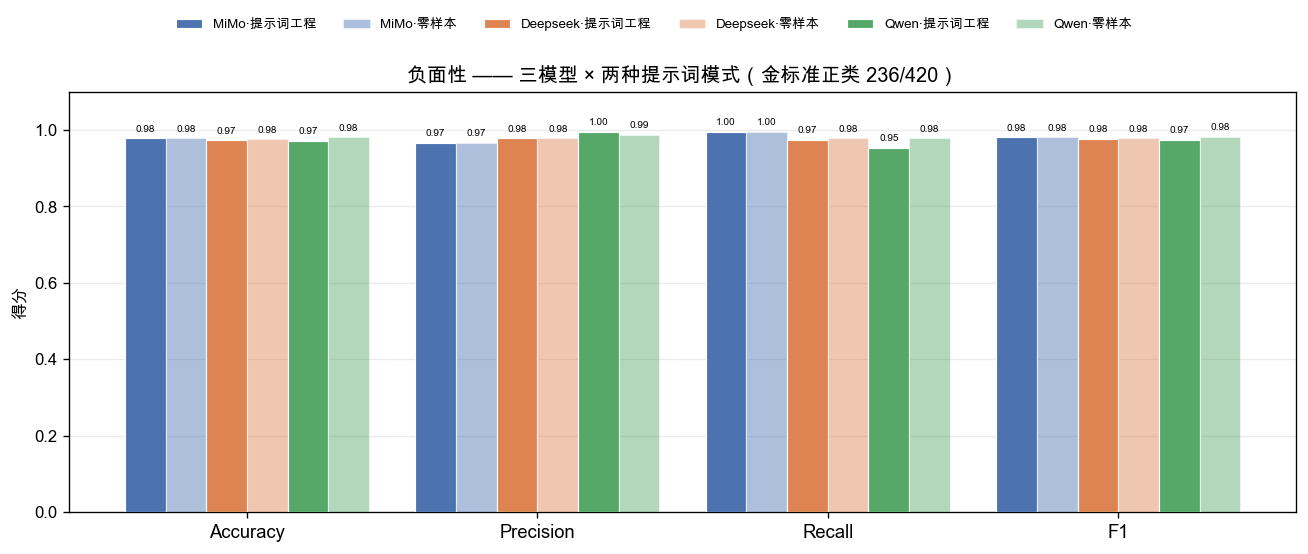

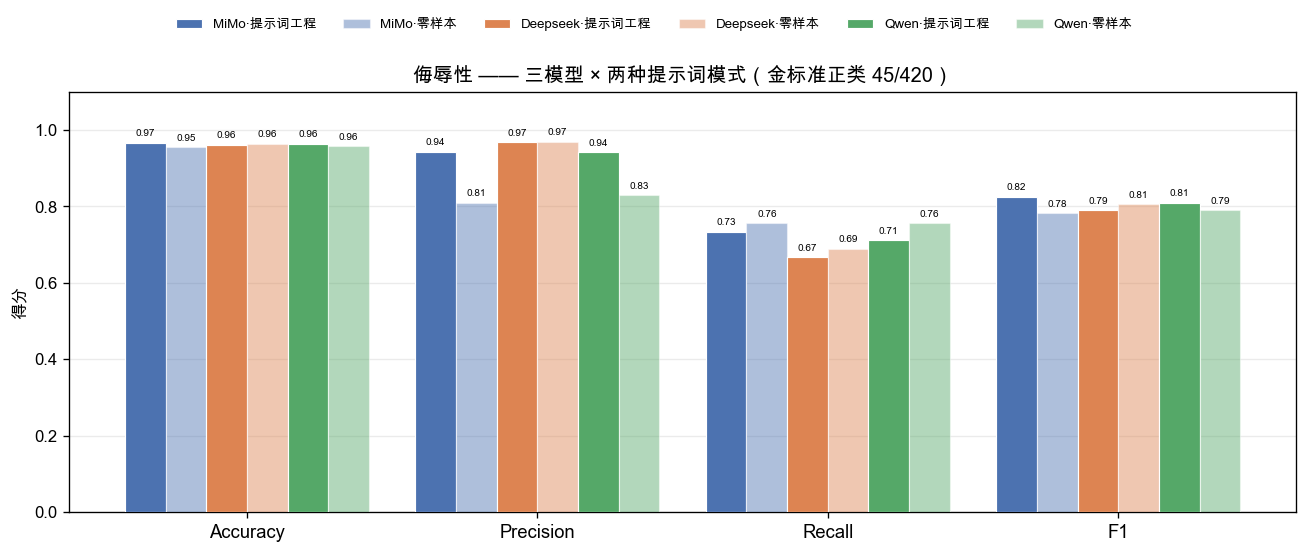

In [15]:
# ===== 图 1/2：四指标分组柱状图（实心=提示词工程，浅色=零样本）=====
def plot_metrics(dim):
    sub = results[results["维度"] == dim]
    n_bars = len(MODELS) * len(MODES_ORDER)
    width = 0.84 / n_bars
    x = np.arange(len(METRICS))

    fig, ax = plt.subplots(figsize=(11, 4.6))
    i = 0
    for model in MODELS:
        for mode in MODES_ORDER:
            vals = [sub[(sub["模型"] == model) & (sub["模式"] == mode)][m].iloc[0]
                    for m in METRICS]
            pos = x + (i - (n_bars - 1) / 2) * width
            ax.bar(pos, vals, width, color=PALETTE[model],
                   alpha=1.0 if mode == "提示词工程" else 0.45,
                   edgecolor="white", linewidth=0.7,
                   label=f"{model}·{mode}", zorder=3)
            for xi, v in zip(pos, vals):
                ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", va="bottom", fontsize=6)
            i += 1

    n_pos = int(human[f"{dim}标签"].sum())
    ax.set_xticks(x)
    ax.set_xticklabels(METRICS, fontsize=11)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("得分", fontsize=10)
    ax.set_title(f"{dim} —— 三模型 × 两种提示词模式（金标准正类 {n_pos}/{len(human)}）", fontsize=12)
    ax.grid(axis="y", alpha=0.25, zorder=0)
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, ncol=6, fontsize=8, frameon=False,
               loc="upper center", bbox_to_anchor=(0.5, 1.005))
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()


for dim in DIMS:
    plot_metrics(dim)

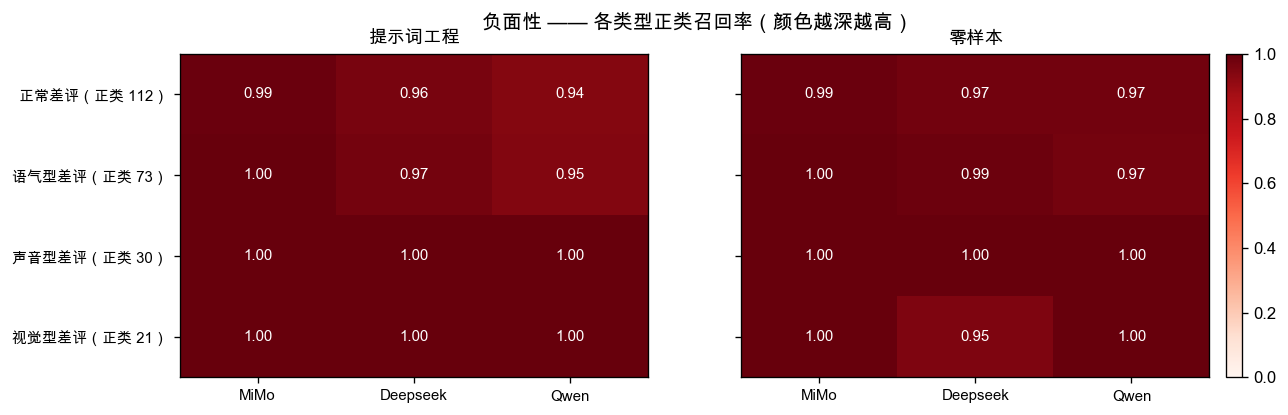

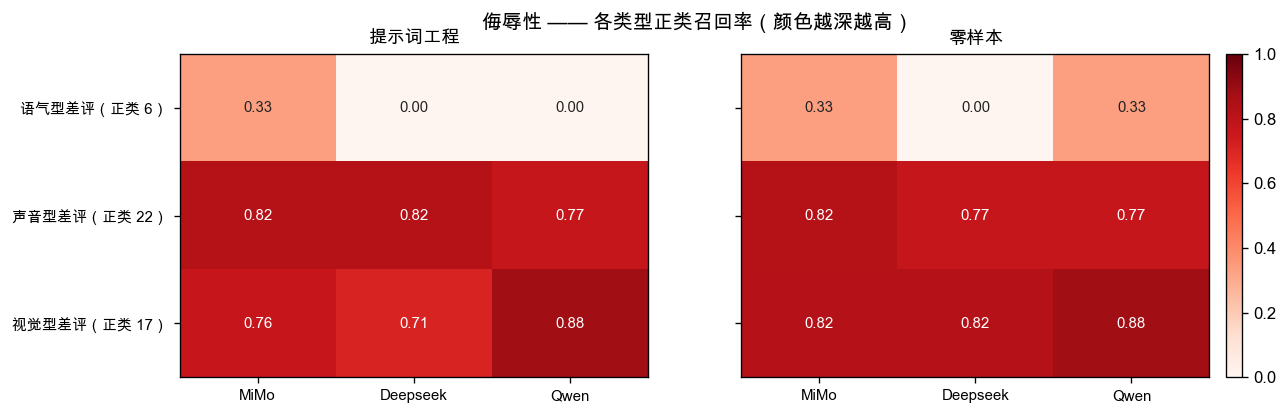

In [16]:
# ===== 图 3/4：各类型正类召回热力图（左=提示词工程，右=零样本）=====
def plot_type_heatmap(dim, types=TYPE_ORDER):
    pos_col = f"{dim}_正类"
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
    for k_ax, (ax, mode) in enumerate(zip(axes, MODES_ORDER)):
        sub = by_type_res[(by_type_res["维度"] == dim) & (by_type_res["模式"] == mode)]
        piv = (sub.pivot(index="类型", columns="模型", values="正类召回")
                  .reindex(index=[t for t in types if t in sub["类型"].unique()],
                           columns=MODELS)
                  .dropna(how="all"))
        im = ax.imshow(piv.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(piv.shape[1]))
        ax.set_xticklabels(piv.columns, fontsize=9)
        ax.set_yticks(range(piv.shape[0]))
        # 只在左图画 y 轴标签，右图留空，避免文字越界压到左图
        ax.set_yticklabels([f"{t}（正类 {int(counts.loc[t, pos_col])}）" for t in piv.index]
                           if k_ax == 0 else [""] * piv.shape[0], fontsize=9)
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                v = piv.values[i, j]
                ax.text(j, i, "—" if np.isnan(v) else f"{v:.2f}",
                        ha="center", va="center", fontsize=9,
                        color="white" if (not np.isnan(v) and v > 0.55) else "#222222")
        ax.set_title(mode, fontsize=11)
    fig.suptitle(f"{dim} —— 各类型正类召回率（颜色越深越高）", fontsize=12)
    fig.colorbar(im, ax=axes, fraction=0.022, pad=0.015)
    plt.show()


for dim in DIMS:
    plot_type_heatmap(dim)

## 六、导出结果

结果写入**新目录** `Results/`，原 CSV 完全不动。

In [17]:
# ===== 导出结果 CSV（新文件，不触碰原 CSV）=====
OUT_DIR = PROJ / "Data/LLM/Results"
if not OUT_DIR.exists():          # 已存在则不重复 mkdir
    OUT_DIR.mkdir(parents=True)

final_table.to_csv(OUT_DIR / "llm_metrics_main.csv", index=False, encoding="utf-8-sig")
ci_table.to_csv(OUT_DIR / "llm_metrics_bootstrap_ci.csv", index=False, encoding="utf-8-sig")
cm.to_csv(OUT_DIR / "llm_metrics_confusion.csv", index=False, encoding="utf-8-sig")
by_type_res.round(4).to_csv(OUT_DIR / "llm_metrics_by_type.csv", index=False, encoding="utf-8-sig")
adv.round(4).to_csv(OUT_DIR / "llm_metrics_adversarial.csv", index=False, encoding="utf-8-sig")
mc_table.to_csv(OUT_DIR / "llm_metrics_mcnemar.csv", index=False, encoding="utf-8-sig")

print("已导出：")
for p in sorted(OUT_DIR.glob("llm_metrics_*.csv")):
    print("  -", p.relative_to(PROJ))

已导出：
  - Data/LLM/Results/llm_metrics_adversarial.csv
  - Data/LLM/Results/llm_metrics_bootstrap_ci.csv
  - Data/LLM/Results/llm_metrics_by_type.csv
  - Data/LLM/Results/llm_metrics_confusion.csv
  - Data/LLM/Results/llm_metrics_main.csv
  - Data/LLM/Results/llm_metrics_mcnemar.csv


## 七、结果解读

**1）Accuracy 不能作为主指标，必须先立基线。**
「侮辱性」正类只占 10.6%（45/420），「全判 0」的退化模型 Accuracy 达 **0.8936**，
但 F1 = 0。因此报告侮辱性任务时必须以 **Precision / Recall / F1** 为主，
Accuracy 仅作辅助，并附上多数类基线。负面性的多数类基线是 56.0%（全判 1）。

**2）两个维度的难度是数量级差异。**
「负面性」接近情感极性识别，三模型 F1 都在 **0.97 以上**（0.9725 ~ 0.9829）；
「侮辱性」是**语用级**判断 —— 要在反讽、谐音、拆字、符号替换中读出攻击意图，
F1 落到 **0.75 ~ 0.79**，且模型间差距被放大。这正说明「侮辱性」才是这项研究
真正的贡献点，「负面性」更像一个已验证的对照任务。

**3）侮辱性任务上模型普遍「保守」：Precision 高、Recall 低。**
Precision 落在 0.77 ~ 0.97，而 Recall 只有 0.62 ~ 0.73 —— 模型宁可漏判也不误判。
若研究目标是「审核覆盖率」，这个偏向是需要讨论的局限；若目标是「减少误伤」，
它反而是优点。务必在结果报告中明确你站在哪一侧。

**4）提示词工程没有带来统计显著的提升。**
McNemar 精确检验的 6 组比较（2 维度 × 3 模型）**全部不显著**（p 值 0.22 ~ 1.00），
ΔF1 在 −0.027 ~ +0.025 之间来回摆动且方向不一致（Qwen 在负面性上甚至零样本更好）。
结论应当写为「在本数据集上，提示词工程未产生可观测的显著增益」，
而不是「提示词工程有效」—— 后者会被审稿人直接挑战。

**5）对抗类型是真正的分水岭，也是最有价值的发现。**
看第三部分与图 3/4：
- 语气型差评（反讽、无脏字）的侮辱性召回极低，最低 **0.000**，最好也只有 **0.333**
- 声音型差评（谐音 / 缩写）召回约 **0.68 ~ 0.77**
- 视觉型差评（拆字 / 符号）召回约 **0.76 ~ 0.88**

结论很清晰：**模型能靠「看见脏字」识别侮辱，但读不懂阴阳怪气。**
「语气型差评」上的塌陷（侮辱性正类仅 6 条，样本极少，需谨慎表述）是全文最值得展开的讨论点。

**6）误报侧表现良好。** 三模型在「好评」上的负面性误报率仅 **0.5% ~ 3.8%**，
侮辱性误报率为 **0.000**。说明低 Recall 不是「乱喊」造成的，而是纯粹的漏判 ——
这进一步支持第 3 点的判断。

**7）解读时的边界。**
① 侮辱性正类只有 45 条，所有以它为分母的比率（尤其分类型的 6 / 22 / 17 条）置信区间都很宽，
Bootstrap CI 已给出参考，正文表述需留余地；
② 金标准里有约 1.4% ~ 1.7% 的条目无法由多数票复现（平票裁量），属人工标注的正常噪声；
③ 两个提示词模式除第 ④ 模块外完全一致，因此 Δ 可解读为「额外提示词的边际效应」，
但不可外推到其他模型或语言。